# Credit card fraud detection

I work in fraud prevention, so I wanted to see how far a model can go on a public dataset and, more importantly, how to pick an alert threshold that makes sense for an operations team.

The dataset is the [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) set from Kaggle: two days of card transactions from European cardholders. Most columns (V1 to V28) are PCA components, so they are anonymized. The only raw ones are `Time`, `Amount` and the label `Class`.

The plan:
1. Clean the data (it has duplicates).
2. Split into train, validation and test.
3. Compare logistic regression, random forest and XGBoost using PR-AUC on validation.
4. Choose the alert threshold on validation.
5. Evaluate once on test and translate the result into money and workload.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

SEED = 42

## 1. Data

In [2]:
df = pd.read_csv('creditcard.csv')
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print(df['Class'].value_counts())
print(f"Fraud rate: {df['Class'].mean():.4%}")

Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


Less than 0.2% of transactions are fraud. That's why accuracy is useless here: a model that never flags anything would score above 99.8%. I'll use precision, recall and PR-AUC instead.

The dataset has no nulls, but it does have exact duplicate rows. If I leave them, the same transaction can end up in both train and test and the results look better than they really are.

In [4]:
print("Nulls:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df.shape)
print(df['Class'].value_counts())

Nulls: 0
Duplicate rows: 1081
After dropping duplicates: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [5]:
# Amount by class
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


## 2. Train / validation / test split

60 / 20 / 20, stratified so each part keeps the same fraud rate.

- **Train**: fit the models.
- **Validation**: compare models and choose the threshold.
- **Test**: used only once at the end.

In my first version of this project I picked the threshold looking at the test set. That leaks information and makes the final numbers too optimistic, so this time the test set stays untouched until the last step.

In [6]:
X = df.drop(columns='Class')
y = df['Class']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

for name, part in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f"{name:5}  rows={len(part):>7,}  fraud={part.sum():>4}")

train  rows=170,235  fraud= 284
val    rows= 56,745  fraud=  94
test   rows= 56,746  fraud=  95


## 3. Model comparison

All models handle the imbalance by weighting the fraud class. Logistic regression goes inside a pipeline with a scaler, because `Time` and `Amount` are on a very different scale from the V columns (without it the solver doesn't even converge).

For XGBoost, `scale_pos_weight` equal to the full class ratio (close to 600 here) pushed almost every probability to the extremes in my first attempt, so I try a few values and keep the best one on validation.

In [7]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Class ratio: {ratio:.0f} to 1")

models = {
    'logistic_regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000)),
    'random_forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', min_samples_leaf=2,
        random_state=SEED, n_jobs=-1),
}

for w in [1, round(np.sqrt(ratio)), round(ratio)]:
    models[f'xgboost_w{w}'] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        scale_pos_weight=w, eval_metric='aucpr',
        random_state=SEED, n_jobs=-1)

Class ratio: 598 to 1


In [8]:
val_proba = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    val_proba[name] = proba
    results.append({'model': name, 'val_pr_auc': average_precision_score(y_val, proba)})

results = pd.DataFrame(results).sort_values('val_pr_auc', ascending=False)
results

,model,val_pr_auc
1,random_forest,0.796516
4,xgboost_w598,0.793120
2,xgboost_w1,0.786995
3,xgboost_w24,0.784625
0,logistic_regression,0.692296


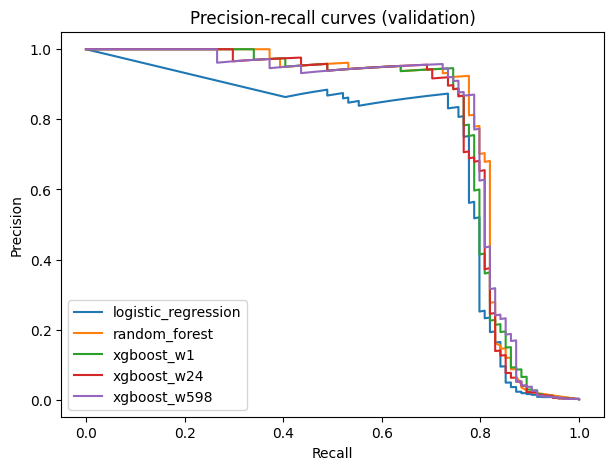

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in val_proba.items():
    prec, rec, _ = precision_recall_curve(y_val, proba)
    ax.plot(rec, prec, label=name)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall curves (validation)')
ax.legend()
plt.show()

Random forest comes out on top, but it's basically tied with XGBoost (0.797 vs 0.793). With only 94 fraud cases in validation, a gap that small is noise, so I wouldn't read it as random forest being clearly better. I keep it because it's the top result and simpler to tune.

Logistic regression is clearly behind (0.69), which makes sense: it can only draw a linear boundary, and the tree models pick up interactions between the components.

In [10]:
best_name = results.iloc[0]['model']
best_model = models[best_name]
print("Best model on validation:", best_name)

Best model on validation: random_forest


## 4. Choosing the threshold

The default 0.5 cutoff isn't necessarily the right one. Lowering it catches more fraud but sends more legitimate transactions to review. I look at the trade-off on validation and keep the threshold with the best F1, which balances both.

In a real team this choice would depend on how many alerts analysts can handle per day and how much a missed fraud costs. F1 is a reasonable default when you don't have those numbers.

In [11]:
proba_val = val_proba[best_name]
n_fraud_val = (y_val == 1).sum()

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (proba_val >= t).astype(int)
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    rec = tp / n_fraud_val
    prec = tp / (tp + fp) if (tp + fp) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    rows.append({'threshold': round(t, 2), 'recall': rec, 'precision': prec,
                 'f1': f1, 'tp': tp, 'fp': fp})

thr_table = pd.DataFrame(rows)
threshold = thr_table.loc[thr_table['f1'].idxmax(), 'threshold']
print("Chosen threshold:", threshold)
thr_table.round(3)

Chosen threshold: 0.35


,threshold,recall,precision,f1,tp,fp
0,0.05,0.819,0.647,0.723,77,42
1,0.10,0.798,0.781,0.789,75,21
2,0.15,0.777,0.811,0.793,73,17
3,0.20,0.777,0.839,0.807,73,14
4,0.25,0.777,0.890,0.830,73,9
5,0.30,0.777,0.912,0.839,73,7
6,0.35,0.777,0.924,0.844,73,6
7,0.40,0.755,0.922,0.830,71,6
8,0.45,0.734,0.920,0.817,69,6
9,0.50,0.734,0.932,0.821,69,5


## 5. Final evaluation on test

First and only time the test set is used.

In [12]:
proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= threshold).astype(int)

print(f"Test PR-AUC: {average_precision_score(y_test, proba_test):.3f}\n")
print(confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test, digits=3))

Test PR-AUC: 0.857

[[56647     4]
 [   22    73]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.948     0.768     0.849        95

    accuracy                          1.000     56746
   macro avg      0.974     0.884     0.924     56746
weighted avg      1.000     1.000     1.000     56746



## 6. What it means for the business

Numbers a fraud team actually cares about: how much money is stopped, how much gets through, and how many alerts someone has to review.

In [13]:
tp_mask = (pred_test == 1) & (y_test == 1)
fn_mask = (pred_test == 0) & (y_test == 1)
fp_mask = (pred_test == 1) & (y_test == 0)

tp, fn, fp = tp_mask.sum(), fn_mask.sum(), fp_mask.sum()
caught = X_test.loc[tp_mask, 'Amount'].sum()
missed = X_test.loc[fn_mask, 'Amount'].sum()

print(f"Fraud caught: {tp} of {tp + fn} ({tp / (tp + fn):.0%})")
print(f"Fraud missed: {fn}")
print(f"False alarms: {fp}")
print()
print(f"Fraud amount stopped: ${caught:,.2f} ({caught / (caught + missed):.0%} of the total)")
print(f"Fraud amount missed:  ${missed:,.2f}")
print()
print(f"Alerts generated: {tp + fp}, of which {tp / (tp + fp):.0%} are real fraud")

Fraud caught: 73 of 95 (77%)
Fraud missed: 22
False alarms: 4

Fraud amount stopped: $9,638.17 (74% of the total)
Fraud amount missed:  $3,334.89

Alerts generated: 77, of which 95% are real fraud


## 7. Which variables matter most

In [14]:
model_for_importance = best_model[-1] if hasattr(best_model, 'steps') else best_model

if hasattr(model_for_importance, 'feature_importances_'):
    importances = pd.Series(model_for_importance.feature_importances_, index=X.columns)
else:
    importances = pd.Series(np.abs(model_for_importance.coef_[0]), index=X.columns)

importances.sort_values(ascending=False).head(10)

,0
V14,0.170435
V12,0.118369
V10,0.117580
V4,0.107402
V17,0.087446
V3,0.063675
V11,0.055864
V16,0.055239
V2,0.026191
V7,0.024132


Since V1 to V28 are PCA components, I can't say what any of these means in business terms (V14 isn't "merchant category" or anything like that). This only tells which components the model relies on.

## Limitations

- The test set has only around 100 fraud cases, so a few transactions change the metrics by several points. Treat the results as an estimate, not an exact figure.
- The split is random, not by time. In production the model would be trained on past data and used on future transactions, which is usually harder.
- Anonymized features mean no real feature engineering and no rule design based on business logic. That's the next thing I want to try on a dataset with raw transaction fields.